# ITNPA4-B34 – Part B: Topic Analysis – Research Document Mining (Questions 3 & 4)
Prototype research-trend tracker: build a corpus data frame from `research_corpus.zip`, denoise it, summarise the articles (TextRank and LSA) and discover topics with LDA + pyLDAvis.
Source of brief: MATANGA, N.Y. 2026.

In [1]:
import os, re, io, json, zipfile, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from IPython.display import Image, display
from wordcloud import WordCloud
import spacy
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
ZIP = '../datasets/research_corpus.zip'; FIG = '../docs/figures'; RES = '../results'
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
results = {}
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}', dpi=150, bbox_inches='tight'); plt.close(); display(Image(f'{FIG}/{name}'))
nlp = spacy.load('en_core_web_sm'); nlp.max_length = 2_000_000

## 3.1 Data frame of all research articles

In [2]:
rows = []
with zipfile.ZipFile(ZIP) as z:
    for name in sorted(z.namelist(), key=lambda n: int(re.search(r'(\d+)', n).group(1)) if re.search(r'\d+', n) else 0):
        if name.endswith('.txt'):
            raw = z.read(name).decode('utf-8', errors='replace')
            first = next(l.strip() for l in raw.splitlines() if l.strip())
            rows.append({'doc_id': int(re.search(r'(\d+)', os.path.basename(name)).group(1)), 'file': name,
                         'first_line': first[:90], 'content': raw})
corpus = pd.DataFrame(rows).sort_values('doc_id').reset_index(drop=True)
corpus['n_chars'] = corpus.content.str.len(); corpus['n_words'] = corpus.content.str.split().str.len()
corpus['n_lines'] = corpus.content.str.count('\n') + 1
# Human-readable title (the files have no metadata; titles identified from the article text)
corpus['title'] = ['Mixed methods research: a research paradigm whose time has come (Johnson & Onwuegbuzie)',
                   "Now I see it, now I don't: researcher's position and reflexivity in qualitative research (Berger)",
                   'Developmental research: studies of instructional design and development (Richey, Klein & Nelson)',
                   "The use of Cronbach's alpha when developing and reporting research instruments in science education (Taber)",
                   "Denzin's paradigm shift: revisiting triangulation in qualitative research (Fusch, Fusch & Ness)"][:len(corpus)]
results['corpus_overview'] = corpus[['doc_id', 'file', 'title', 'n_chars', 'n_words', 'n_lines']].to_dict('records')
corpus[['doc_id', 'file', 'title', 'n_chars', 'n_words', 'n_lines', 'content']]

,doc_id,file,title,n_chars,n_words,n_lines,content
0,1,research_corpus/research_1.txt,Mixed methods research: a research paradigm wh...,38598,5602,439,The purposes of this article are to position m...
1,2,research_corpus/research_2.txt,"Now I see it, now I don't: researcher's positi...",16279,2416,176,"Now I see it, now I don’t:\r\nresearcher’s pos..."
2,3,research_corpus/research_3.txt,Developmental research: studies of instruction...,26521,3828,368,DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCT...
3,4,research_corpus/research_4.txt,The use of Cronbach's alpha when developing an...,39072,5922,123,Abstract\r\nCronbach’s alpha is a statistic co...
4,5,research_corpus/research_5.txt,Denzin's paradigm shift: revisiting triangulat...,27142,4027,312,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [3]:
for i, r in corpus.iterrows(): print(f"--- research_{r.doc_id}.txt ---\n{r.content[:300]!r}\n")

--- research_1.txt ---
'The purposes of this article are to position mixed methods research\r\n(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism\r\nas offering an attractive philosophical partner for mixed methods research, and to provide a frame'

--- research_2.txt ---
'Now I see it, now I don’t:\r\nresearcher’s position and\r\nreflexivity in qualitative\r\nresearch\r\nRoni Berger\r\nAdelphi University, USA\r\nAbstract\r\nThis article addresses potential effects on reflexivity of researcher’s social position (e.g.\r\ngender, age, race, immigration status, sexual orientation), pers'

--- research_3.txt ---
'DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCTIONAL DESIGN AND DEVELOPMENT\r\nRita C. Richey\r\nWayne State University\r\nJames D. Klein\r\nArizona State University\r\nWayne A. Nelson\r\nSouthern Illinois University at Edwardsville\r\n41.1 INTRODUCTION\r\nThe field of instructional technology has trad

> **Observation:** the brief describes the corpus as "recent AI research articles", but on inspection the five texts are research-**methodology** papers (mixed methods, reflexivity, developmental research, Cronbach's alpha, triangulation). The pipeline is domain-agnostic, so the analysis is carried out on the corpus as supplied and the topics are interpreted accordingly.

## 3.2 Preprocessing (state-of-the-art denoising)

In [4]:
CITATION = re.compile(r"\((?:[^()]*?\b(?:19|20)\d{2}[a-z]?\b[^()]*?)\)")   # (Author, 2004; ...)
URL = re.compile(r"https?://\S+|www\.\S+|doi:\s*\S+", re.I)
EMAIL = re.compile(r"\S+@\S+")
SECTION_NO = re.compile(r"\b\d+(\.\d+)+\b")
BOILERPLATE = re.compile(r"similar content being viewed|^(chapter|article)\b.*(©|open access)|full size image|^fig(ure)?\.?\s*\d+|"
                         r"^\d{1,2} (january|february|march|april|may|june|july|august|september|october|november|december) \d{4}$|"
                         r"\b(university|college|institute|department)\b|^corresponding author|^e-?mail:|^\d{4}$|^article$|^[\w./-]{25,}$", re.I)
def is_heading_or_meta(line, idx):
    """Front matter, affiliations, web boilerplate and Title-Case section headings."""
    l = line.strip()
    if not l: return True
    if BOILERPLATE.search(l) and len(l.split()) <= 20: return True
    words = re.findall(r"[A-Za-z][A-Za-z'’]*", l)
    if words and len(words) <= 12 and not re.search(r"[.?!,;:]$", l):
        caps = sum(w[0].isupper() for w in words) / len(words)
        if caps >= 0.6: return True                                   # headings / author names
    return False
def strip_front_matter(text):
    lines = text.splitlines()
    return "\n".join(l for i, l in enumerate(lines) if not is_heading_or_meta(l, i))
def normalise_layout(text):
    """Unicode/ligature normalisation, boilerplate removal, de-hyphenation and re-flowing of PDF line breaks."""
    text = unicodedata.normalize('NFKC', text)                       # ligatures such as 'ﬁ' -> 'fi'
    text = strip_front_matter(text)
    text = text.translate(str.maketrans({'\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"', '\u2013': '-', '\u2014': ' - ', '\u00a0': ' '}))
    text = re.sub(r'(\w)-\n(\w)', r'\1\2', text)                      # words split across lines
    text = re.sub(r'\s*\n\s*', ' ', text)                              # hard line breaks -> spaces
    return re.sub(r'\s+', ' ', text).strip()
def denoise_sentences_text(text):
    """Readable but cleaned text used for summarisation (keeps sentence structure)."""
    t = normalise_layout(text)
    for pat in (CITATION, URL, EMAIL, SECTION_NO): t = pat.sub(' ', t)
    t = re.sub(r'\[[^\]]*\]', ' ', t)
    t = re.sub(r'([.,;:)])\d{1,2}(?:,\s*\d{1,2})*(?=\s|$)', r'\1', t)      # footnote markers e.g. 'dispute.1'
    t = re.sub(r'\bSource:[^.]*?(?=[A-Z][a-z]+ )', ' ', t)                        # table/figure source captions                                   # bracketed notes
    return re.sub(r'\s+([.,;:])', r'\1', re.sub(r'\s+', ' ', t)).strip()
corpus['clean_text'] = corpus.content.apply(denoise_sentences_text)
print(corpus.clean_text[1][:500])

Now I see it, now I don't: researcher's position and reflexivity in qualitative research This article addresses potential effects on reflexivity of researcher's social position (e.g. gender, age, race, immigration status, sexual orientation), personal experiences, and political and professional beliefs. Because reflexivity is a major strategy for quality control in qualitative research, understanding how it may be impacted by the characteristics and experiences of the researcher is of paramount 


In [5]:
DOMAIN_STOP = {'et', 'al', 'research', 'researcher', 'study', 'article', 'paper', 'use', 'also', 'may', 'one', 'two', 'e.g', 'i.e',
               'university', 'journal', 'press', 'vol', 'page', 'author', 'chapter', 'make', 'well', 'way', 'much', 'many', 'often'}
KEEP_POS = {'NOUN', 'ADJ', 'VERB', 'PROPN'}
DROP_ENTS = {'PERSON', 'GPE', 'DATE', 'CARDINAL', 'ORDINAL', 'PERCENT', 'MONEY', 'QUANTITY', 'TIME'}
def to_tokens(doc):
    out = []
    for t in doc:
        if t.ent_type_ in DROP_ENTS or not t.is_alpha or t.is_stop or t.pos_ not in KEEP_POS: continue
        lem = t.lemma_.lower()
        if len(lem) > 2 and lem not in DOMAIN_STOP and lem not in nlp.Defaults.stop_words: out.append(lem)
    return out
docs_spacy = list(nlp.pipe(corpus.clean_text))
def unique_sents(doc):
    """Keep sentences with >= 6 words and drop exact duplicates (article 1 contains a repeated block of text)."""
    seen, out = set(), []
    for s in doc.sents:
        key = re.sub(r'\W+', ' ', s.text.lower()).strip()
        if len(s.text.split()) >= 6 and key not in seen: seen.add(key); out.append(s)
    return out
uniq = [unique_sents(d) for d in docs_spacy]
corpus['n_sentences_raw'] = [sum(1 for s in d.sents if len(s.text.split()) >= 6) for d in docs_spacy]
corpus['sentences'] = [[s.text.strip() for s in u] for u in uniq]
sent_tokens = [[to_tokens(s) for s in u] for u in uniq]
print('Duplicate sentences removed per article:', (corpus.n_sentences_raw - corpus.sentences.str.len()).tolist())
# Learn collocations (bigrams) with gensim Phrases on sentence-level token streams
from gensim.models.phrases import Phrases, Phraser, ENGLISH_CONNECTOR_WORDS
phrases = Phraser(Phrases([s for d in sent_tokens for s in d], min_count=4, threshold=8, connector_words=ENGLISH_CONNECTOR_WORDS))
sent_tokens = [[phrases[s] for s in d] for d in sent_tokens]
corpus['tokens'] = [[t for s in d for t in s] for d in sent_tokens]
corpus['n_tokens_clean'] = corpus.tokens.str.len()
corpus['n_bigrams'] = corpus.tokens.apply(lambda ts: sum('_' in t for t in ts))
corpus['n_sentences'] = corpus.sentences.str.len()
bigram_vocab = pd.Series([t for ts in corpus.tokens for t in ts if '_' in t]).value_counts()
results['top_bigrams'] = bigram_vocab.head(20).to_dict()
results['preprocessing'] = corpus[['doc_id', 'n_words', 'n_tokens_clean', 'n_bigrams', 'n_sentences_raw', 'n_sentences']].to_dict('records')
print('Most frequent learned bigrams:\n', bigram_vocab.head(20))
corpus[['doc_id', 'n_words', 'n_tokens_clean', 'n_bigrams', 'n_sentences_raw', 'n_sentences']]

Duplicate sentences removed per article: [76, 0, 0, 0, 1]
Most frequent learned bigrams:
 mixed_method                    35
science_education               29
internal_consistency            19
value_alpha                     17
design_development              16
alpha_value                     16
methodological_triangulation    14
cronbach_alpha                  12
data_collection                 11
case_design                     11
multiple_source                 10
quantitative_qualitative         9
social_change                    9
qualitative_quantitative         8
instructional_design             8
development_process              8
instructional_technology         7
type_developmental               7
reliability_internal             7
mitigate_bias                    7
Name: count, dtype: int64


,doc_id,n_words,n_tokens_clean,n_bigrams,n_sentences_raw,n_sentences
0,1,5602,1104,35,152,76
1,2,2416,892,11,59,59
2,3,3828,1505,55,154,154
3,4,5922,2320,122,183,183
4,5,4027,1488,117,154,153


 | mixed methods research. In doing this, we briefly review the para

TOKENS: purpose position mixed_method mixed synonym natural complement traditional qualitative_quantitative present pragmatism offer attractive philosophical partner mixed_method provide framework design conduct mixed_method review paradigm war incompatibility thesis commonality quantitative_qualitative explain tenet pragmatism explain fundamental principle mixed apply provide specific set design major type mixed_method mix model design mixed_method design explain mixed_method follow step process key feature mixed_method methodological pluralism eclecticism result


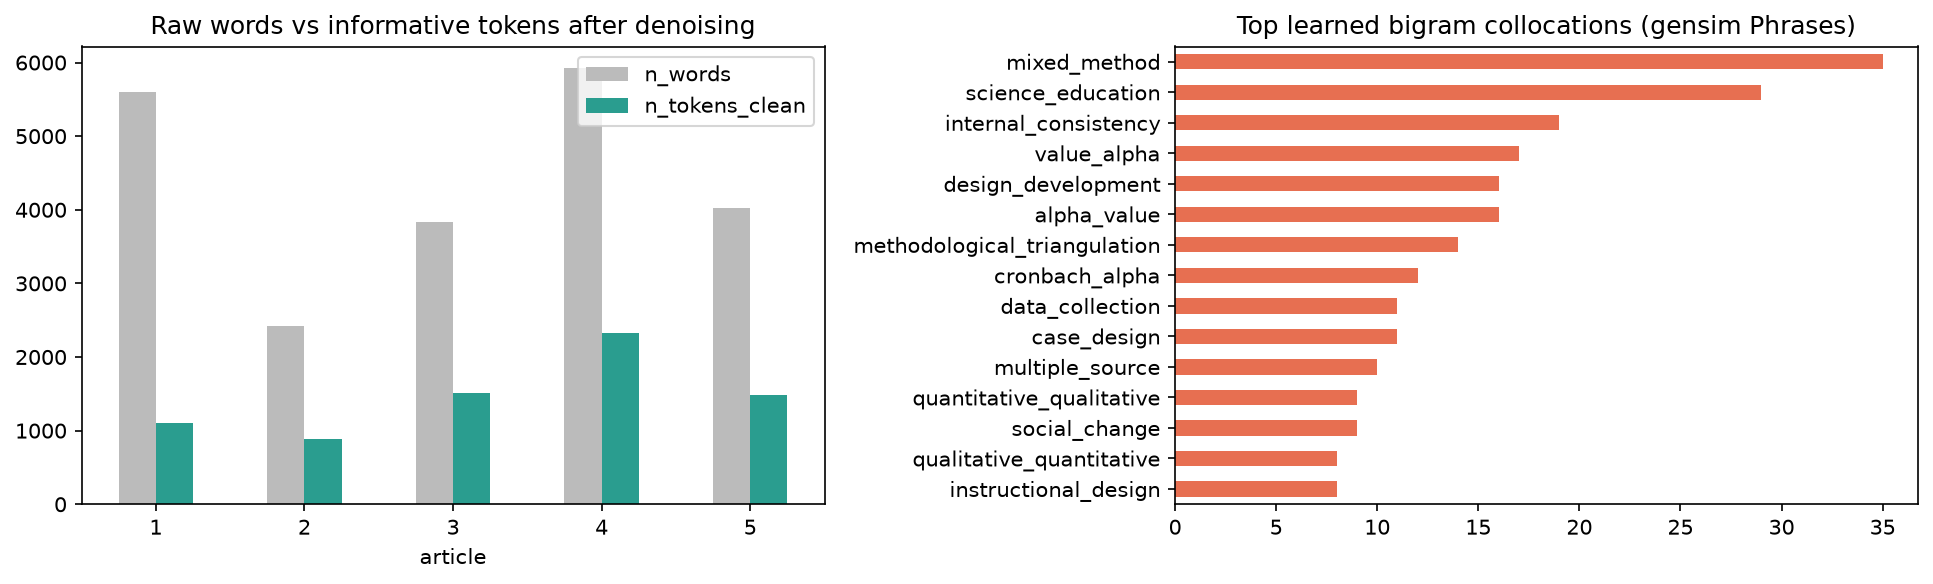

In [6]:
print('RAW   :', corpus.content[0][:400].replace('\n', ' | ')); print('\nTOKENS:', ' '.join(corpus.tokens[0][:60]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
corpus.set_index('doc_id')[['n_words', 'n_tokens_clean']].plot.bar(ax=ax[0], rot=0, color=['#bbbbbb', '#2a9d8f']); ax[0].set_title('Raw words vs informative tokens after denoising'); ax[0].set_xlabel('article')
bigram_vocab.head(15)[::-1].plot.barh(ax=ax[1], color='#e76f51'); ax[1].set_title('Top learned bigram collocations (gensim Phrases)')
savefig('q3_2_preprocessing.png')
corpus.drop(columns=['content']).assign(tokens=corpus.tokens.apply(' '.join), sentences=corpus.sentences.apply(lambda s: ' || '.join(s))).to_csv('../datasets/research_corpus_clean.csv', index=False)

## 3.3 Summary of the first article – extractive TextRank

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
def textrank(sentences, token_lists, top_n=6, damping=0.85):
    docs = [' '.join(t) for t in token_lists]
    X = TfidfVectorizer().fit_transform(docs)
    sim = cosine_similarity(X); np.fill_diagonal(sim, 0)
    G = nx.from_numpy_array(sim)
    scores = nx.pagerank(G, alpha=damping, weight='weight')
    ranked = sorted(scores, key=scores.get, reverse=True)
    chosen = sorted(ranked[:top_n])                         # keep original order for readability
    return chosen, scores, G
s1, t1 = corpus.sentences[0], sent_tokens[0]
chosen1, scores1, G1 = textrank(s1, t1, top_n=6)
summary1 = ' '.join(s1[i] for i in chosen1)
results['q33_summary'] = summary1; results['q33_selected_idx'] = chosen1
results['q33_compression'] = {'sentences_in': len(s1), 'sentences_out': len(chosen1), 'words_in': int(sum(len(x.split()) for x in s1)), 'words_out': len(summary1.split())}
print(f"TextRank summary of article 1 ({len(chosen1)} of {len(s1)} sentences):\n")
for i in chosen1: print(f'[{i}] (score {scores1[i]:.4f}) {s1[i]}\n')

TextRank summary of article 1 (6 of 76 sentences):

[0] (score 0.0203) The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

[15] (score 0.0237) Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis, which posits that qualitative and quantitative research paradigms, including their associated methods, cannot and should not be mixed.

[20] (score 0.0216) Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.

[43] (score 0.0264) For example, qualitative researchers should be free to use quantitative methods, and quantitative re

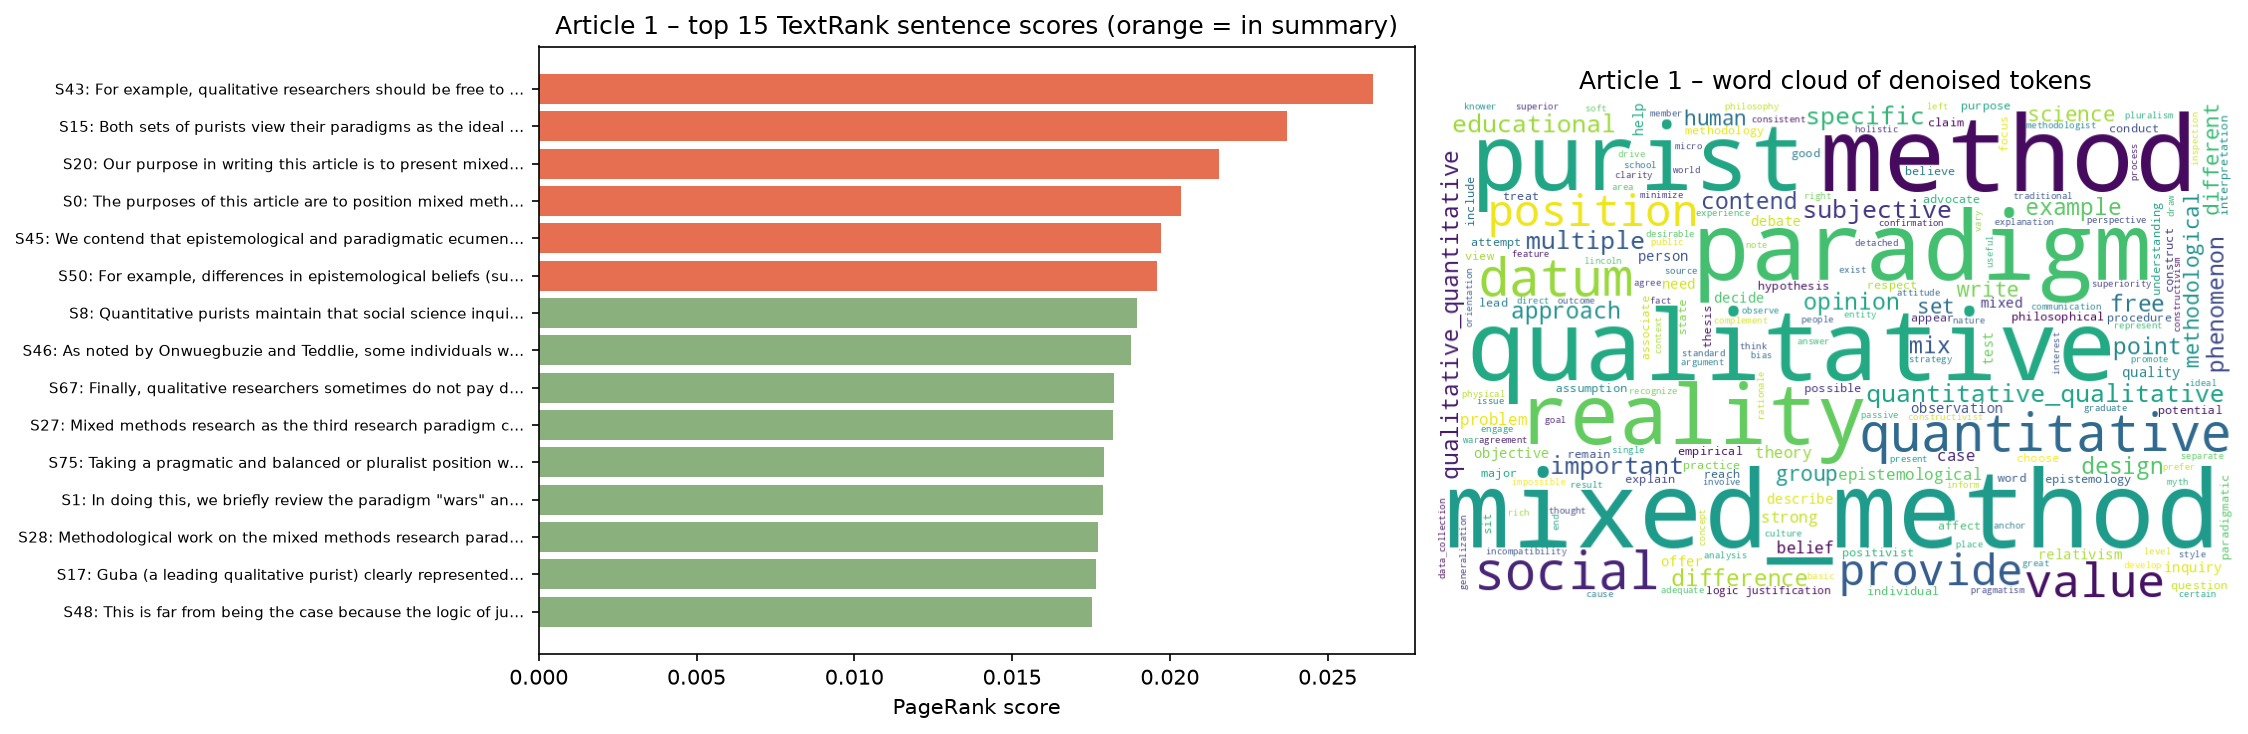

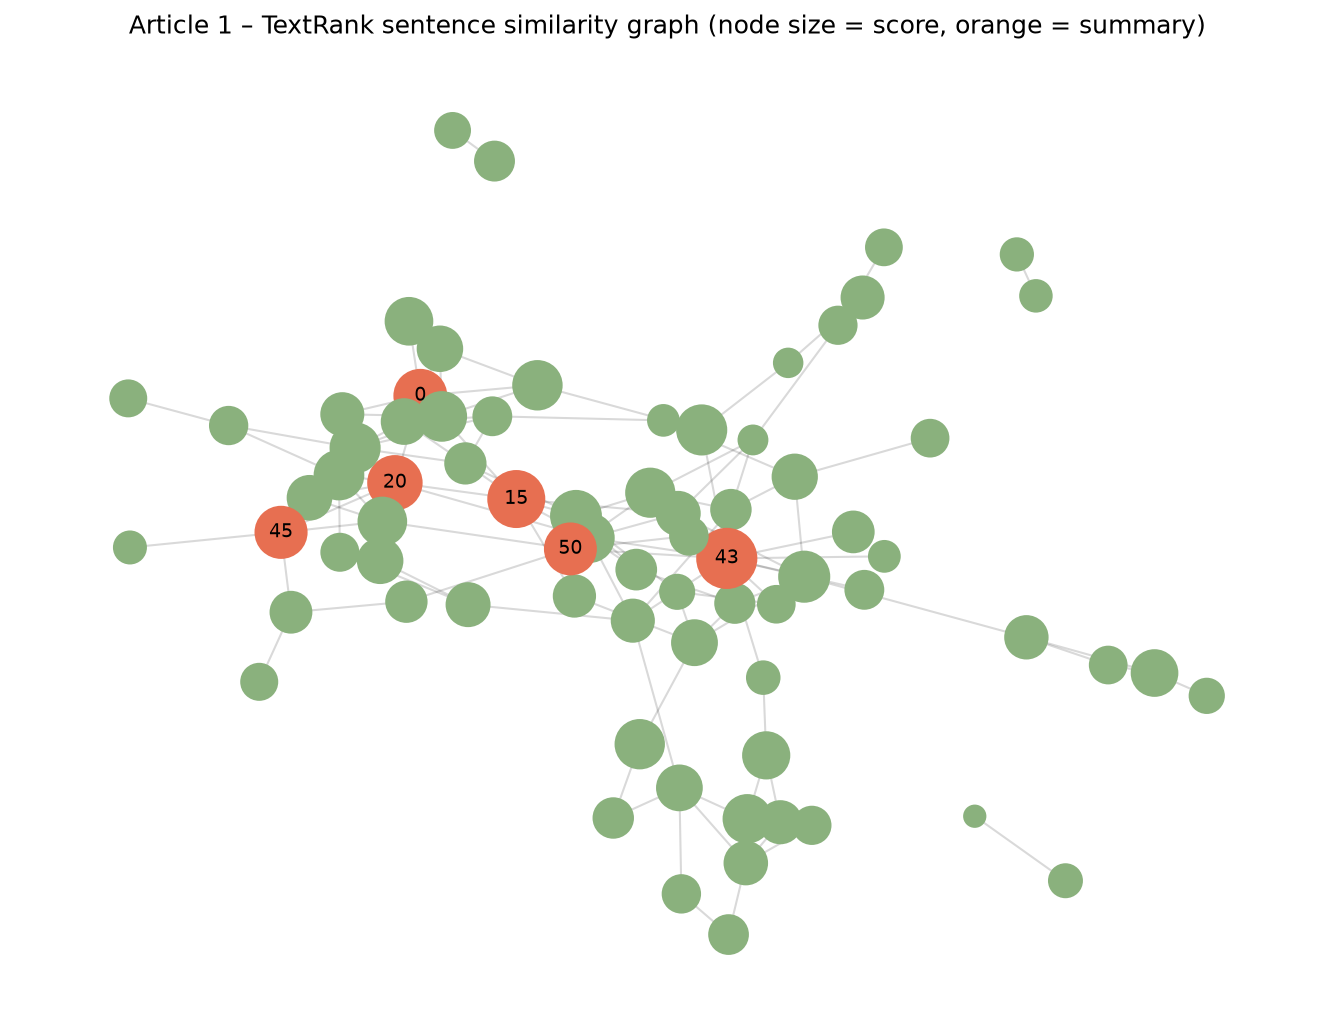

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.1, 1]})
sc = pd.Series(scores1).sort_values(ascending=False).head(15)[::-1]
ax[0].barh([f'S{i}: ' + s1[i][:55] + '…' for i in sc.index], sc.values, color=['#e76f51' if i in chosen1 else '#8ab17d' for i in sc.index])
ax[0].set_title('Article 1 – top 15 TextRank sentence scores (orange = in summary)'); ax[0].set_xlabel('PageRank score'); ax[0].tick_params(axis='y', labelsize=7)
wc = WordCloud(width=800, height=500, background_color='white', colormap='viridis', random_state=RANDOM_STATE).generate(' '.join(corpus.tokens[0]))
ax[1].imshow(wc); ax[1].axis('off'); ax[1].set_title('Article 1 – word cloud of denoised tokens')
savefig('q3_3_article1_textrank.png')
# sentence-similarity graph used by TextRank
plt.figure(figsize=(9, 7))
H = nx.Graph([(u, v, d) for u, v, d in G1.edges(data=True) if d['weight'] > 0.12])
pos = nx.spring_layout(H, seed=RANDOM_STATE, weight='weight')
nx.draw_networkx_edges(H, pos, alpha=0.15)
nx.draw_networkx_nodes(H, pos, node_size=[4000 * scores1[n] * len(s1) / 10 for n in H.nodes], node_color=['#e76f51' if n in chosen1 else '#8ab17d' for n in H.nodes])
nx.draw_networkx_labels(H, pos, labels={n: str(n) for n in chosen1 if n in H}, font_size=9)
plt.title('Article 1 – TextRank sentence similarity graph (node size = score, orange = summary)'); plt.axis('off')
savefig('q3_3_article1_textrank_graph.png')
top_terms1 = pd.Series(corpus.tokens[0]).value_counts().head(15); results['q33_top_terms'] = top_terms1.to_dict()

## 3.4 Aggregate summary of the remaining articles – LSA (Latent Semantic Analysis) summarisation

In [9]:
from sklearn.decomposition import TruncatedSVD
rest = corpus.iloc[1:].reset_index(drop=True)
agg_sents, agg_toks, agg_src = [], [], []
for k, r in rest.iterrows():
    for s, t in zip(r.sentences, sent_tokens[k + 1]):
        if len(t) >= 3: agg_sents.append(s); agg_toks.append(' '.join(t)); agg_src.append(int(r.doc_id))
vec_s = TfidfVectorizer(min_df=2, sublinear_tf=True); A = vec_s.fit_transform(agg_toks)   # sentences x terms
N_CONCEPTS = 8
svd = TruncatedSVD(n_components=N_CONCEPTS, random_state=RANDOM_STATE); U = svd.fit_transform(A)   # U*Sigma (sentence x concept)
# Steinberger & Jezek (2004) sentence score: length of the sentence vector in the weighted latent space
lsa_score = np.sqrt((U ** 2).sum(axis=1))
# Gong & Liu (2001) concept-wise selection: for each latent concept take the sentence that loads most strongly on it,
# which gives coverage of all main themes; remaining slots are filled by the Steinberger & Jezek score.
TOP = 10
def novel(i, chosen): return all(cosine_similarity(A[i], A[j])[0, 0] < 0.5 for j in chosen)
chosen = []
for c in range(N_CONCEPTS):
    for i in np.argsort(-np.abs(U[:, c])):
        if i not in chosen and novel(i, chosen): chosen.append(int(i)); break
for i in np.argsort(-lsa_score):
    if len(chosen) >= TOP: break
    if i not in chosen and novel(i, chosen): chosen.append(int(i))
concept_of = {i: (f'Concept {chosen.index(i) + 1}' if chosen.index(i) < N_CONCEPTS else 'S&J score') for i in chosen}
chosen = sorted(chosen, key=lambda i: (agg_src[i], i))
agg_summary = pd.DataFrame({'article': [agg_src[i] for i in chosen], 'selected_by': [concept_of[i] for i in chosen], 'lsa_score': lsa_score[chosen].round(4), 'sentence': [agg_sents[i] for i in chosen]})
results['q34_summary'] = agg_summary.to_dict('records')
results['q34_stats'] = {'sentences_in': len(agg_sents), 'sentences_out': TOP, 'terms': int(A.shape[1]), 'explained_variance_ratio_total': round(float(svd.explained_variance_ratio_.sum()), 4)}
terms = np.array(vec_s.get_feature_names_out())
concepts = {f'Concept {c+1}': terms[np.argsort(-svd.components_[c])[:8]].tolist() for c in range(N_CONCEPTS)}
results['q34_concepts'] = concepts
for c, w in concepts.items(): print(c, ':', ', '.join(w))
pd.set_option('display.max_colwidth', 300); agg_summary

Concept 1 : instrument, report, scale, alpha, reliability, knowledge, datum, triangulation
Concept 2 : triangulation, datum, method, denzin, methodological_triangulation, qualitative, multiple_source, mixed_method
Concept 3 : development, process, developmental, instructional, design, evaluation, knowledge, design_development
Concept 4 : science_education, statistic, field, publish, alpha, survey, volume, development
Concept 5 : development, scale, datum, reliability, term, instructional, internal_consistency, triangulation
Concept 6 : design, method, mixed_method, example, scale, case_design, instructional_system, item
Concept 7 : knowledge, student, understanding, design, instrument, report, test, production
Concept 8 : reliability, design, term, mixed_method, result, alpha, describe, qualitative


,article,selected_by,lsa_score,sentence
0,2,Concept 5,0.4358,"Benefits and challenges to reflexivity under three types of researcher's position are discussed and illustrated by means of case examples: (1) reflexivity when researcher shares the experience of study participants, (2) reflexivity when researcher moves from the position of an outsider to the po..."
1,3,Concept 3,0.4317,"While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes."
2,4,Concept 4,0.6115,"This paper presents findings from that survey, to illustrate the extent and nature of the use of Cronbach's alpha in published reports of science education in highly regarded journals in the field, as well as exploring identified issues of concern by discussing examples from the literature consu..."
3,4,Concept 8,0.5559,Alpha is commonly reported for the development of scales intended to measure attitudes and other affective constructs.
4,4,Concept 1,0.5651,"However, the literature also includes reports of the development of tests of student knowledge and understanding that cite Cronbach's alpha as an indicator of instrument quality."
5,4,S&J score,0.5779,"It would be suspect if the correlations between these scales were very high, as that would suggest that the sets of items making up the different scales were not measuring different factors."
6,4,Concept 7,0.5035,"This instrument was said to measure ""knowledge level of biotechnology and genetics"" and it was reported that ""the reliability (Cronbach's α) of the knowledge questionnaire was.721"" (p.2930)."
7,5,S&J score,0.6685,Using triangulation such as multiple sources of data contributes to the reliability of results and saturation of data.
8,5,Concept 6,0.5779,"However, along with its benefits, a mixed-methods design has a great deal of complexity in the data collection methods - much more than other designs."
9,5,Concept 2,0.5905,"Since Denzin initially defined the four types of triangulation in social research, there has been confusion between data triangulation and methodological triangulation."


In [10]:
print('AGGREGATE LSA SUMMARY OF ARTICLES 2-5:\n'); print(' '.join(agg_summary.sentence))

AGGREGATE LSA SUMMARY OF ARTICLES 2-5:

Benefits and challenges to reflexivity under three types of researcher's position are discussed and illustrated by means of case examples: (1) reflexivity when researcher shares the experience of study participants, (2) reflexivity when researcher moves from the position of an outsider to the position of an insider in the course of the study, and (3) reflexivity when researcher has no personal familiarity or experience with what is being studied. While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes. This paper presents findings from that survey, to illustrate the extent and nature of the use of Cronbach's alpha in published reports of science education in highly regarded journals in the field, as well as exploring identified issues of concern by discussing examples from the literature consulted. Alpha

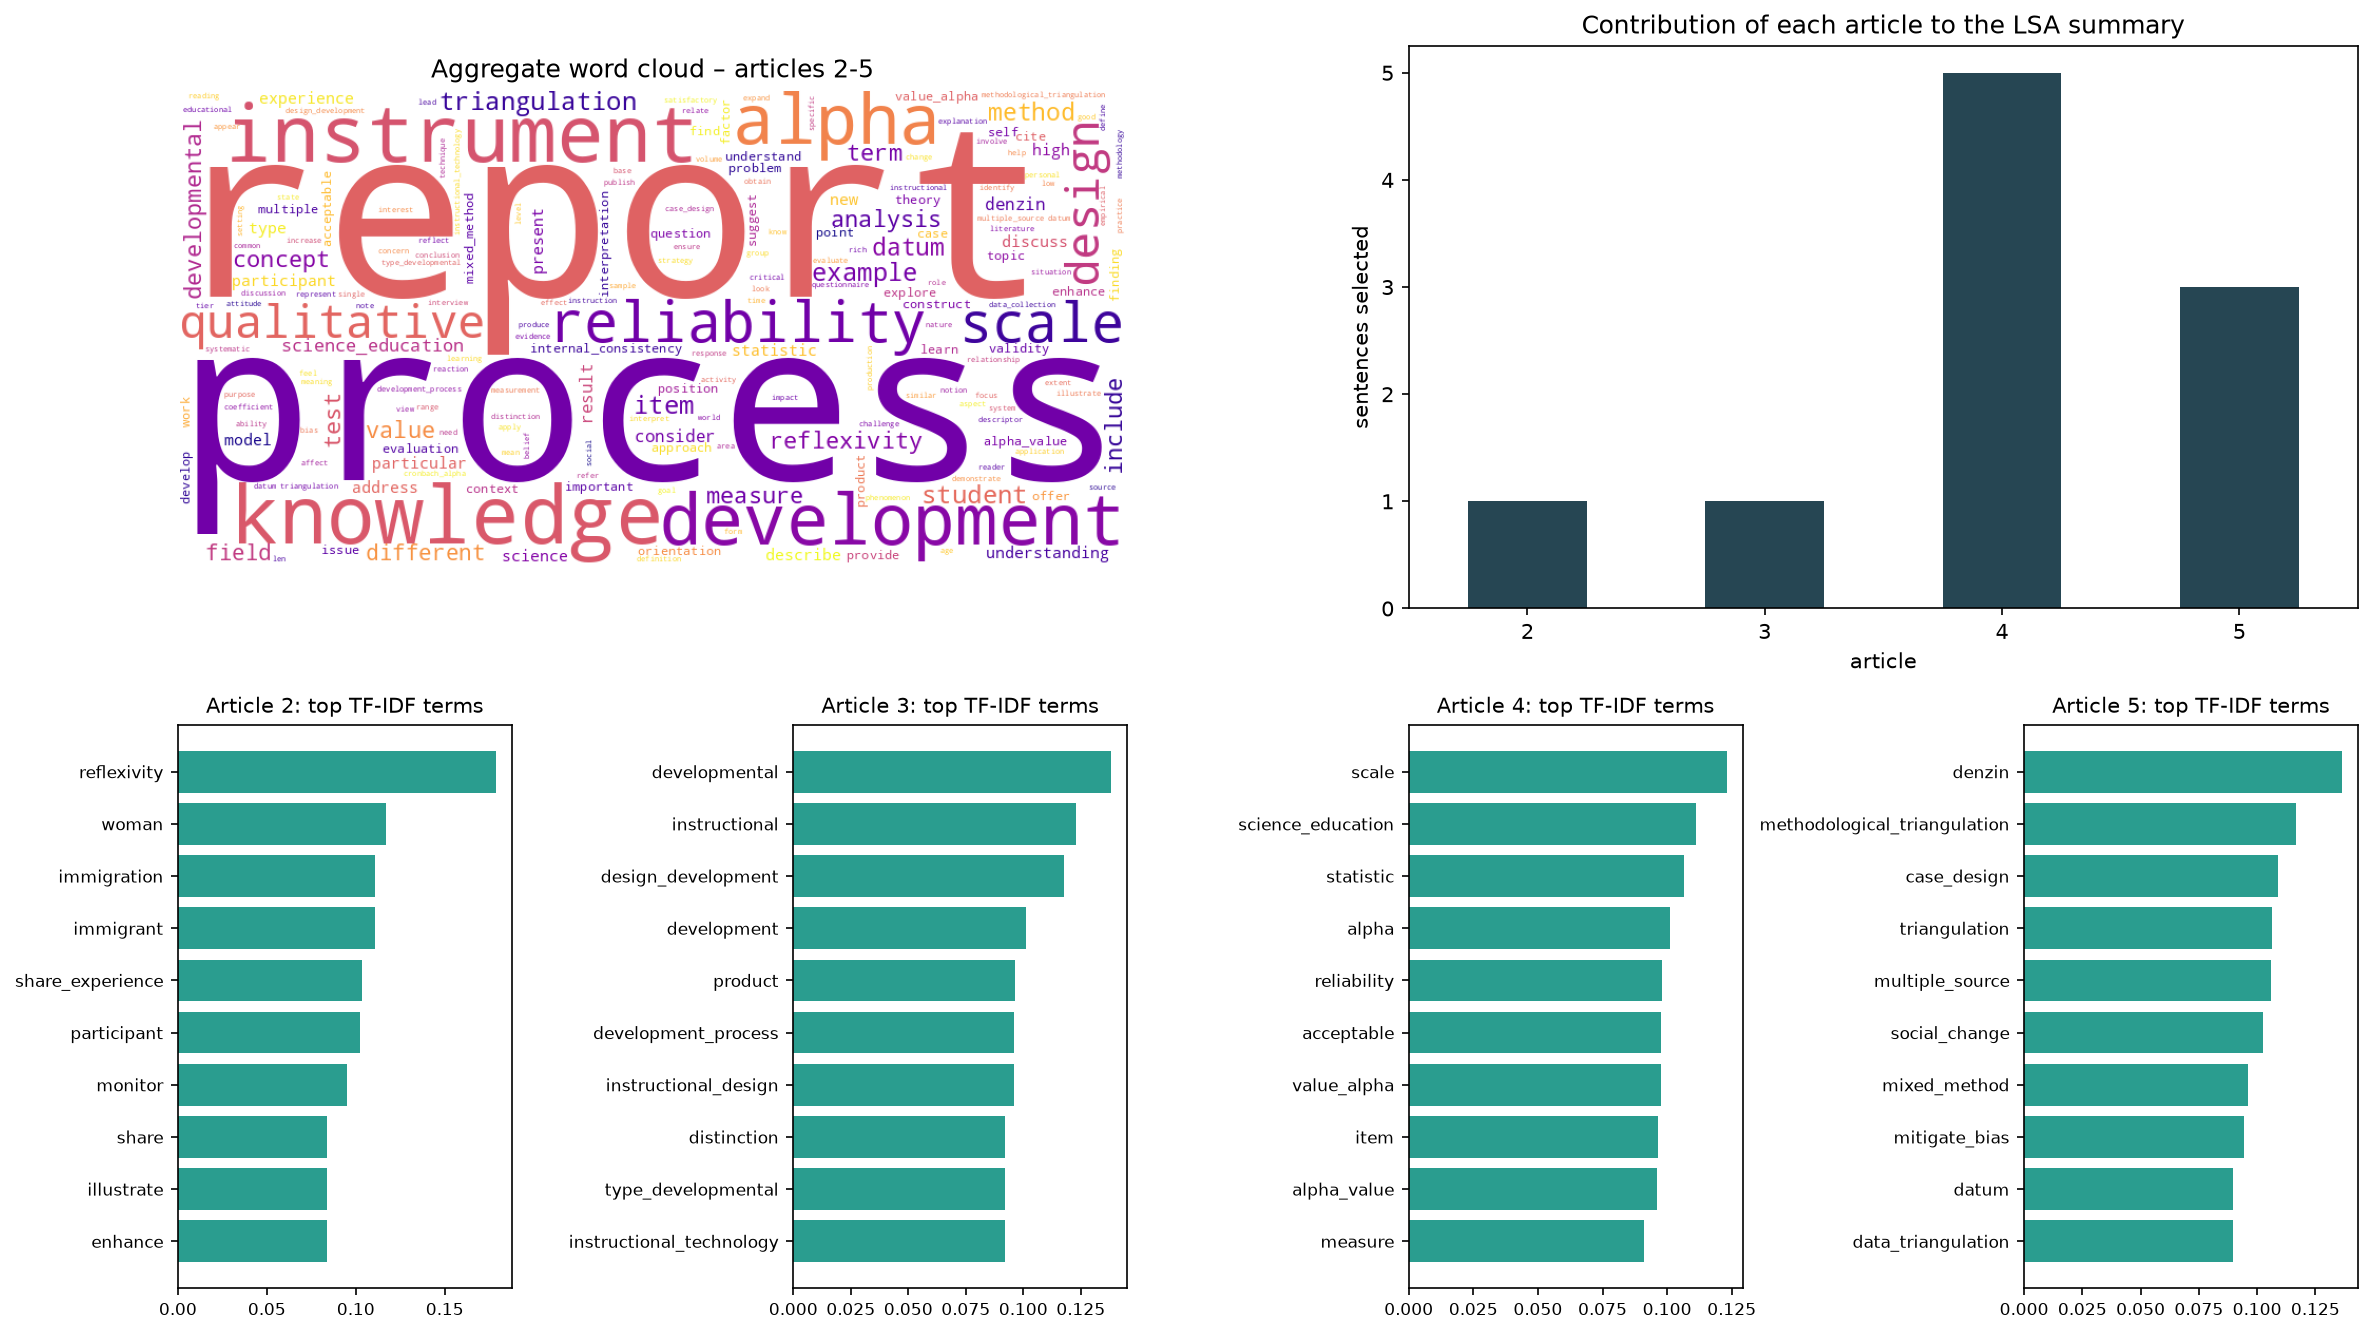

In [11]:
# Visual 1: aggregate word cloud + top TF-IDF terms per remaining article
doc_vec = TfidfVectorizer(sublinear_tf=True); D = doc_vec.fit_transform(corpus.tokens.apply(' '.join)); dterms = np.array(doc_vec.get_feature_names_out())
fig = plt.figure(figsize=(16, 9)); gs = fig.add_gridspec(2, 4)
axw = fig.add_subplot(gs[0, :2]); axw.imshow(WordCloud(width=900, height=450, background_color='white', colormap='plasma', random_state=RANDOM_STATE).generate(' '.join(t for ts in rest.tokens for t in ts))); axw.axis('off'); axw.set_title('Aggregate word cloud – articles 2-5')
axs = fig.add_subplot(gs[0, 2:]); pd.Series([agg_src[i] for i in chosen]).value_counts().reindex(rest.doc_id, fill_value=0).plot.bar(ax=axs, rot=0, color='#264653'); axs.set_title('Contribution of each article to the LSA summary'); axs.set_xlabel('article'); axs.set_ylabel('sentences selected')
tfidf_top = {}
for j, (k, r) in enumerate(rest.iterrows()):
    row = D[k + 1].toarray().ravel(); idx = np.argsort(-row)[:10]; tfidf_top[int(r.doc_id)] = dterms[idx].tolist()
    a = fig.add_subplot(gs[1, j]); a.barh(dterms[idx][::-1], row[idx][::-1], color='#2a9d8f'); a.set_title(f'Article {r.doc_id}: top TF-IDF terms', fontsize=10); a.tick_params(labelsize=8)
results['q34_tfidf_top_terms'] = tfidf_top
savefig('q3_4_aggregate_overview.png')

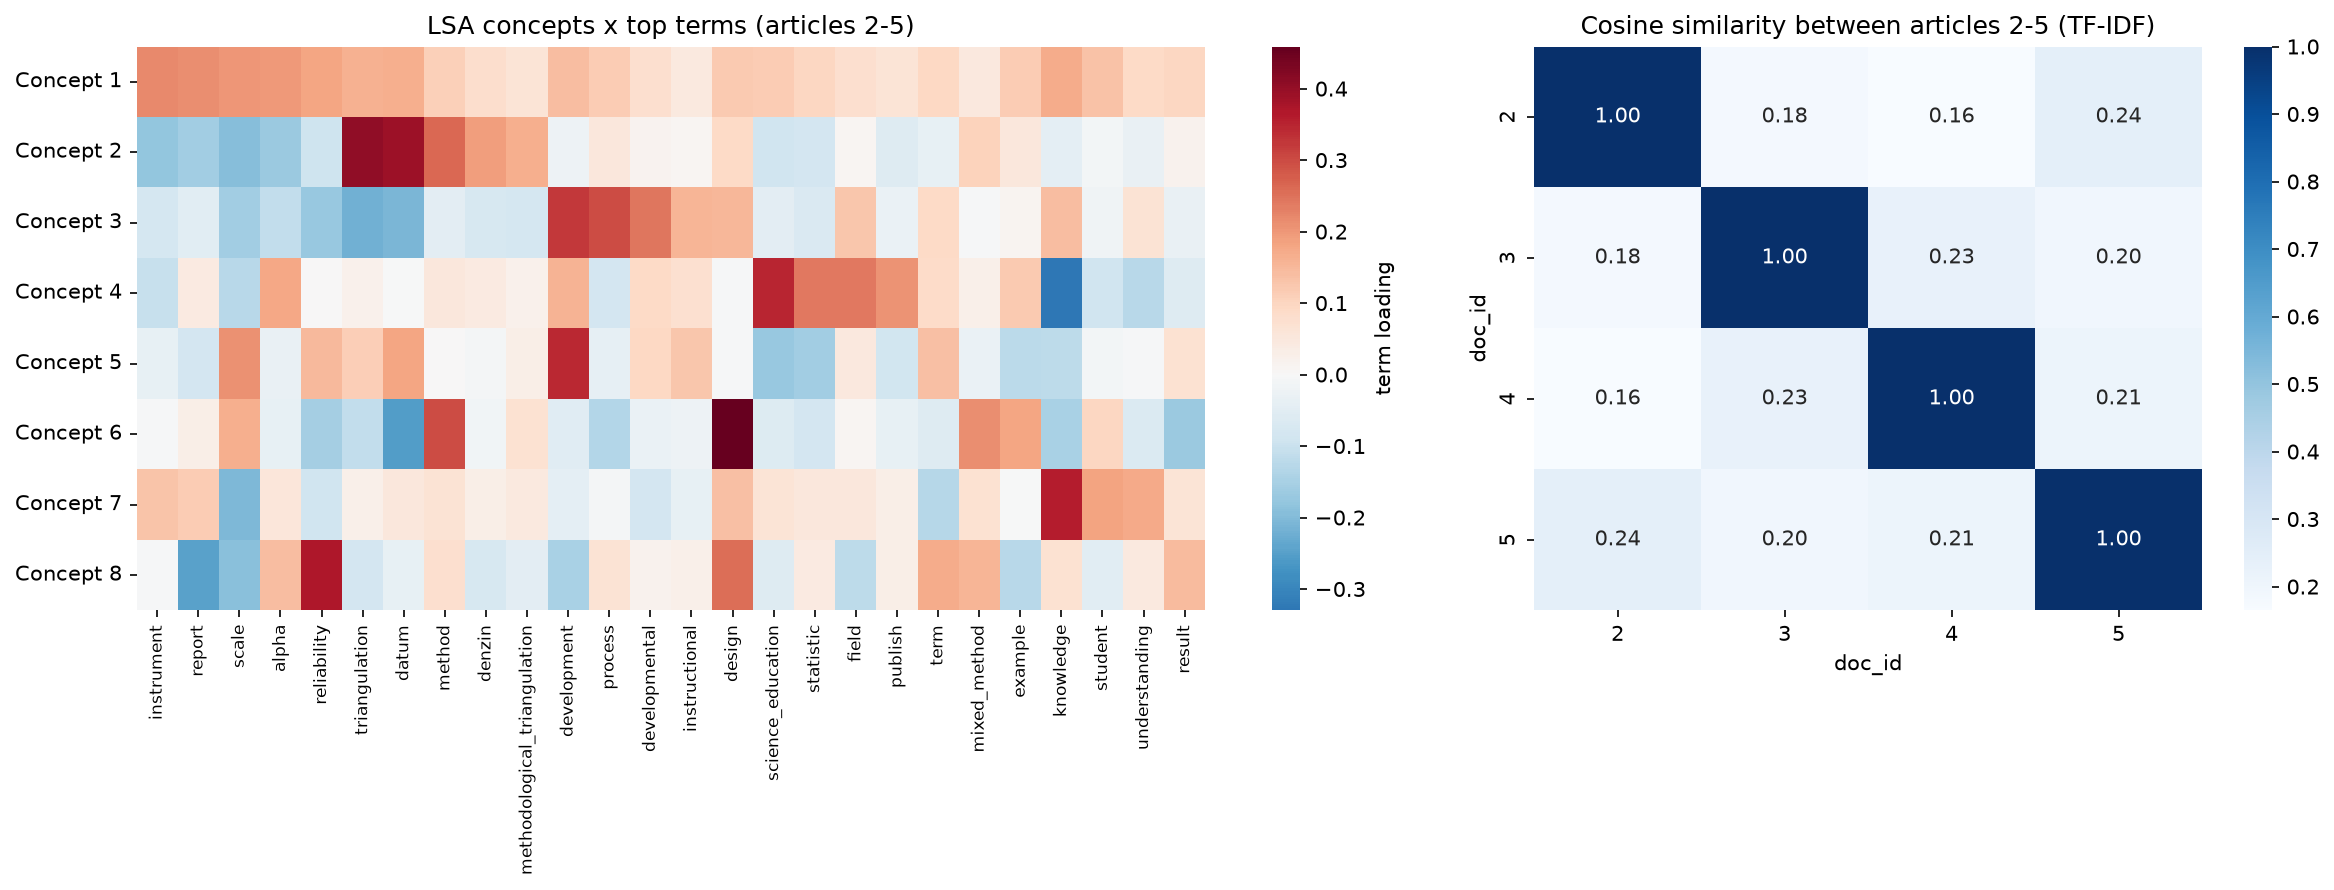

In [12]:
# Visual 2: LSA concept-term heat-map and article similarity heat-map
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.6, 1]})
top_terms = list(dict.fromkeys([t for w in concepts.values() for t in w[:5]]))
M = pd.DataFrame(svd.components_[:, [list(terms).index(t) for t in top_terms]], index=list(concepts), columns=top_terms)
sns.heatmap(M, cmap='RdBu_r', center=0, ax=ax[0], cbar_kws={'label': 'term loading'}); ax[0].set_title('LSA concepts x top terms (articles 2-5)'); ax[0].tick_params(axis='x', labelsize=8)
S = cosine_similarity(D[1:]); sns.heatmap(pd.DataFrame(S, index=rest.doc_id, columns=rest.doc_id), annot=True, fmt='.2f', cmap='Blues', ax=ax[1]); ax[1].set_title('Cosine similarity between articles 2-5 (TF-IDF)')
savefig('q3_4_lsa_concepts_similarity.png')
results['q34_doc_similarity'] = pd.DataFrame(S, index=rest.doc_id, columns=rest.doc_id).round(3).to_dict()

## 4.1 Latent Dirichlet Allocation (gensim)

With only five articles LDA would have too few documents to estimate topic mixtures, so each article is split into passages of ~10 consecutive sentences (a standard practice for long documents). Topic distributions are then aggregated back to article level.

In [13]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
CHUNK = 10
passages, p_doc = [], []
for k, d in enumerate(sent_tokens):
    for s in range(0, len(d), CHUNK):
        toks = [t for x in d[s:s + CHUNK] for t in x]
        if len(toks) >= 20: passages.append(toks); p_doc.append(int(corpus.doc_id[k]))
dictionary = Dictionary(passages); dictionary.filter_extremes(no_below=3, no_above=0.5)
bow = [dictionary.doc2bow(p) for p in passages]
print('Passages:', len(passages), '| vocabulary after filtering:', len(dictionary))
results['lda_setup'] = {'passages': len(passages), 'vocab': len(dictionary), 'chunk_sentences': CHUNK}
def train_lda(k, seed=RANDOM_STATE):
    return LdaModel(bow, num_topics=k, id2word=dictionary, passes=30, iterations=400, alpha='auto', eta='auto', random_state=seed, chunksize=len(bow))
SEEDS = [42, 7, 2026]   # LDA is stochastic: average coherence over several random initialisations
coh, models = [], {}
for k in range(2, 11):
    for seed in SEEDS:
        m = train_lda(k, seed); models[(k, seed)] = m
        cv = CoherenceModel(model=m, texts=passages, dictionary=dictionary, coherence='c_v').get_coherence()
        um = CoherenceModel(model=m, corpus=bow, dictionary=dictionary, coherence='u_mass').get_coherence()
        coh.append({'k': k, 'seed': seed, 'c_v': cv, 'u_mass': um, 'log_perplexity': m.log_perplexity(bow)})
coh_runs = pd.DataFrame(coh)
coh = coh_runs.groupby('k').agg(c_v=('c_v', 'mean'), c_v_std=('c_v', 'std'), u_mass=('u_mass', 'mean'), log_perplexity=('log_perplexity', 'mean')).round(4).reset_index()
coh = pd.DataFrame(coh); results['coherence'] = coh.to_dict('records'); coh

Passages: 65 | vocabulary after filtering: 583


,k,c_v,c_v_std,u_mass,log_perplexity
0,2,0.3947,0.0718,-2.5849,-5.9659
1,3,0.4860,0.0183,-2.0169,-5.9093
2,4,0.4250,0.0668,-2.8283,-5.9831
3,5,0.4243,0.0899,-3.1257,-6.0203
4,6,0.4645,0.0313,-2.7098,-6.0038
5,7,0.4405,0.0035,-2.8781,-6.0251
6,8,0.4708,0.0476,-2.3980,-6.0490
7,9,0.4657,0.0416,-2.4335,-6.0880
8,10,0.4724,0.0240,-2.6086,-6.0821


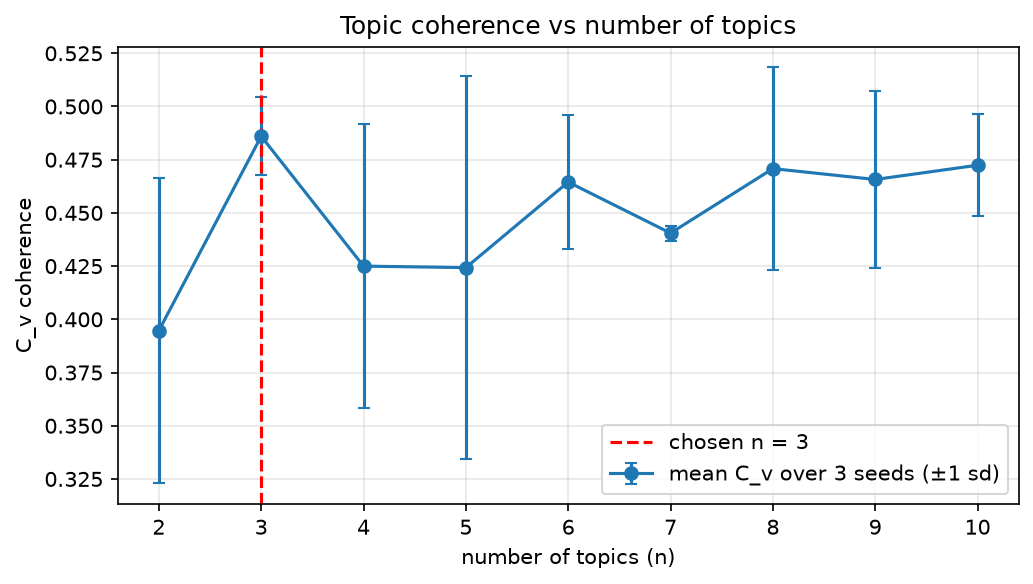

Chosen n = 3 | mean C_v = 0.486 | final model seed 42 C_v = 0.4984


In [14]:
# Parsimony rule: smallest n whose C_v is within 0.01 of the best score (avoids over-splitting a 5-article corpus)
BEST_K = int(coh[coh.c_v >= coh.c_v.max() - 0.01].k.min()); results['best_k'] = BEST_K
fig, ax = plt.subplots(figsize=(7, 4)); ax.errorbar(coh.k, coh.c_v, yerr=coh.c_v_std, fmt='o-', capsize=3, label=f'mean C_v over {len(SEEDS)} seeds (±1 sd)'); ax.axvline(BEST_K, ls='--', c='red', label=f'chosen n = {BEST_K}')
ax.set_xlabel('number of topics (n)'); ax.set_ylabel('C_v coherence'); ax.set_title('Topic coherence vs number of topics'); ax.legend(); ax.grid(alpha=0.3)
savefig('q4_1_coherence.png')
best_seed = int(coh_runs[coh_runs.k == BEST_K].sort_values('c_v', ascending=False).seed.iloc[0])
lda = models[(BEST_K, best_seed)]; results['best_seed'] = best_seed
results['final_model_c_v'] = round(float(coh_runs[(coh_runs.k == BEST_K) & (coh_runs.seed == best_seed)].c_v.item()), 4)
print('Chosen n =', BEST_K, '| mean C_v =', coh.loc[coh.k == BEST_K, 'c_v'].item(), '| final model seed', best_seed, 'C_v =', results['final_model_c_v'])

In [15]:
topic_words = {}
for t in range(BEST_K):
    topic_words[t + 1] = [(w, round(float(p), 4)) for w, p in lda.show_topic(t, topn=10)]
tw = pd.DataFrame({f'Topic {t}': [f'{w} ({p:.3f})' for w, p in ws] for t, ws in topic_words.items()})
results['topic_words'] = topic_words
results['topic_coherence_per_topic'] = [round(float(x), 4) for x in CoherenceModel(model=lda, texts=passages, dictionary=dictionary, coherence='c_v').get_coherence_per_topic()]
print('Per-topic C_v:', results['topic_coherence_per_topic'])
tw

Per-topic C_v: [0.7239, 0.4464, 0.3249]


,Topic 1,Topic 2,Topic 3
0,instrument (0.028),process (0.023),datum (0.035)
1,report (0.026),development (0.022),triangulation (0.028)
2,alpha (0.024),developmental (0.015),method (0.027)
3,scale (0.022),reflexivity (0.013),qualitative (0.023)
4,reliability (0.021),knowledge (0.013),denzin (0.013)
5,item (0.020),design (0.012),design (0.012)
6,measure (0.015),evaluation (0.010),multiple (0.011)
7,test (0.015),model (0.009),participant (0.010)
8,science_education (0.014),instructional (0.009),mixed_method (0.010)
9,student (0.013),product (0.009),point (0.010)


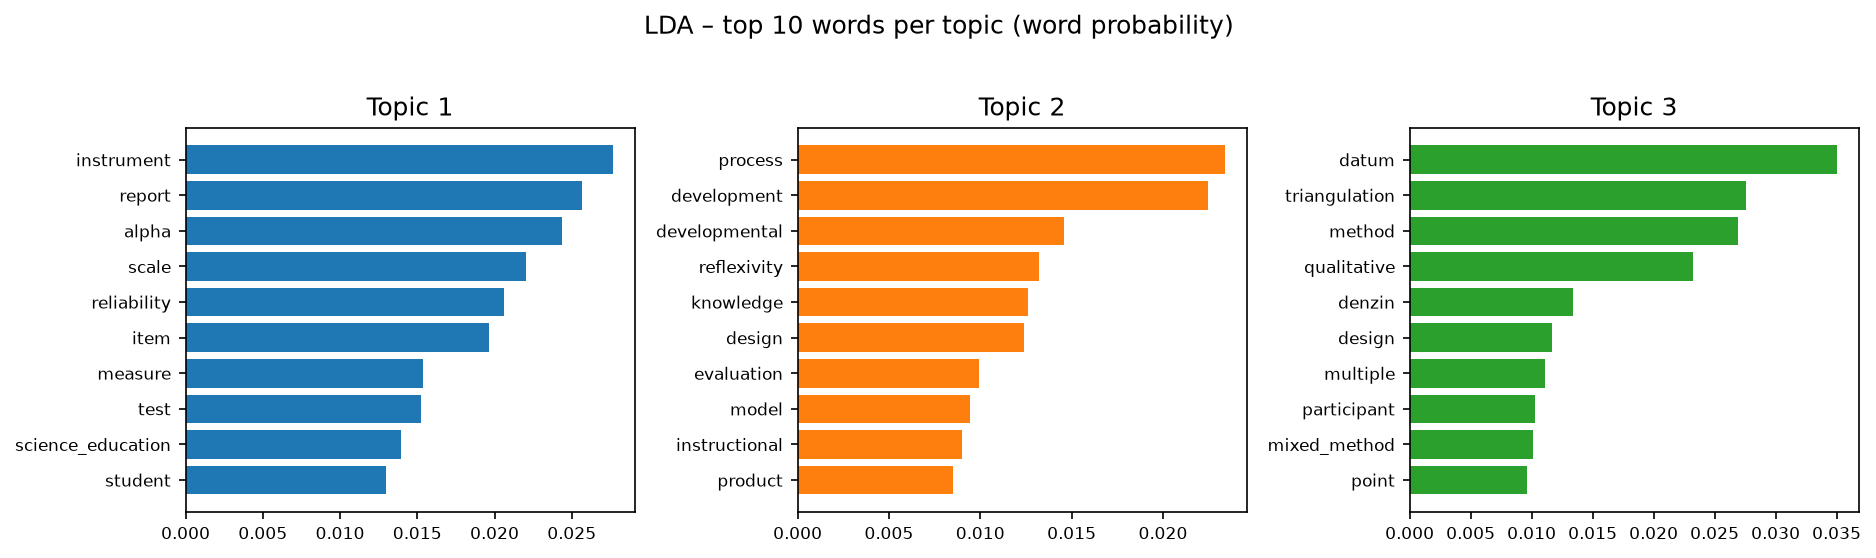

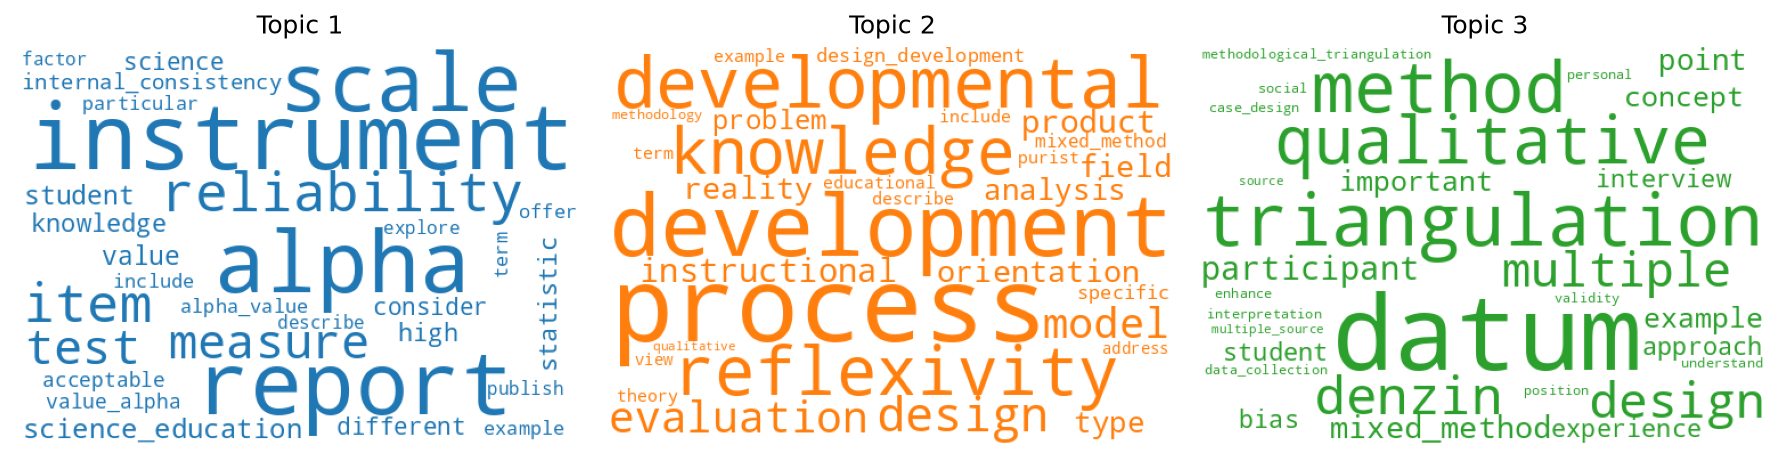

In [16]:
cols = min(BEST_K, 4); rows_ = int(np.ceil(BEST_K / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.6 * rows_)); axes = np.array(axes).ravel()
pal = sns.color_palette('tab10', BEST_K)
for t in range(BEST_K):
    w, p = zip(*lda.show_topic(t, topn=10)); axes[t].barh(w[::-1], p[::-1], color=pal[t]); axes[t].set_title(f'Topic {t+1}'); axes[t].tick_params(labelsize=8)
for a in axes[BEST_K:]: a.axis('off')
fig.suptitle('LDA – top 10 words per topic (word probability)', y=1.02)
savefig('q4_1_topic_words.png')
fig, axes = plt.subplots(1, BEST_K, figsize=(4 * BEST_K, 3.2)); axes = np.atleast_1d(axes)
for t in range(BEST_K):
    axes[t].imshow(WordCloud(width=500, height=350, background_color='white', color_func=lambda *a, c=pal[t], **k: tuple(int(255 * x) for x in c), random_state=RANDOM_STATE).generate_from_frequencies(dict(lda.show_topic(t, topn=30))))
    axes[t].axis('off'); axes[t].set_title(f'Topic {t+1}')
savefig('q4_1_topic_wordclouds.png')

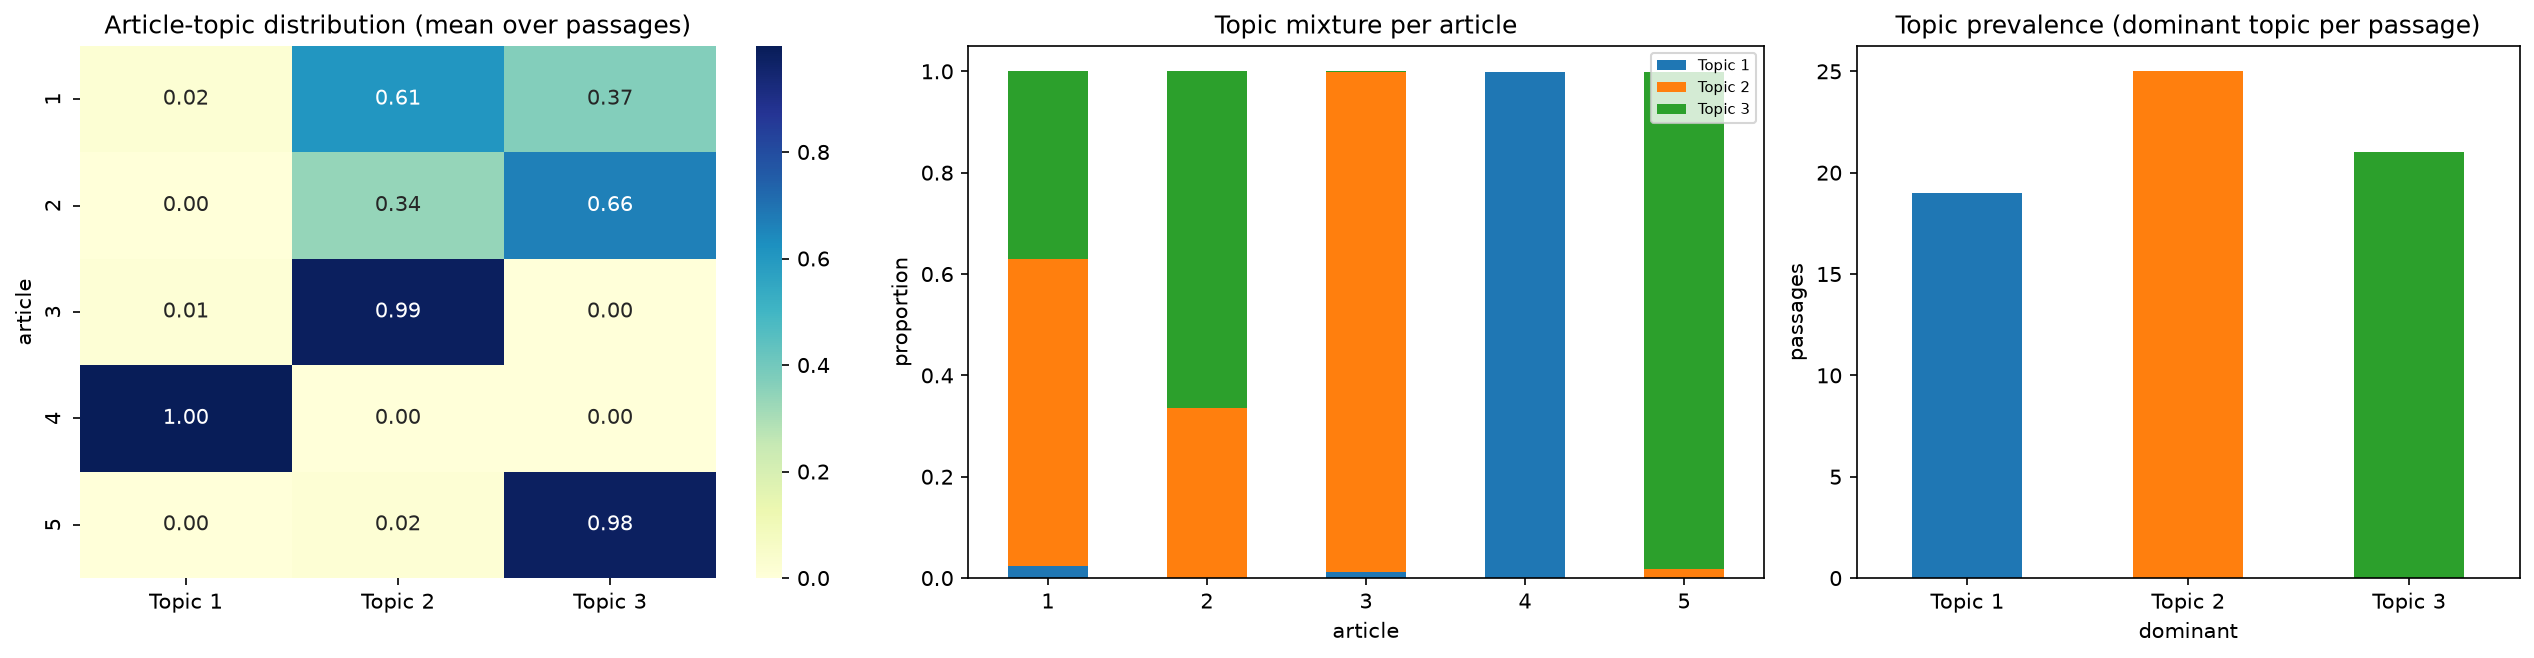

,Topic 1,Topic 2,Topic 3,dominant_topic
article,,,,
1,0.023,0.607,0.370,Topic 2
2,0.000,0.336,0.664,Topic 3
3,0.012,0.987,0.001,Topic 2
4,0.999,0.000,0.000,Topic 1
5,0.000,0.018,0.981,Topic 3


In [17]:
theta = np.zeros((len(bow), BEST_K))
for i, b in enumerate(bow):
    for t, p in lda.get_document_topics(b, minimum_probability=0): theta[i, t] = p
pt = pd.DataFrame(theta, columns=[f'Topic {t+1}' for t in range(BEST_K)]); pt['article'] = p_doc
doc_topic = pt.groupby('article').mean().round(3)
doc_topic['dominant_topic'] = doc_topic.idxmax(axis=1)
results['doc_topic'] = doc_topic.reset_index().to_dict('records')
pt['dominant'] = pt.drop(columns='article').idxmax(axis=1)
results['topic_prevalence'] = pt['dominant'].value_counts().sort_index().to_dict()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1.2, 1.2, 1]})
sns.heatmap(doc_topic.drop(columns='dominant_topic'), annot=True, fmt='.2f', cmap='YlGnBu', ax=ax[0]); ax[0].set_title('Article-topic distribution (mean over passages)')
doc_topic.drop(columns='dominant_topic').plot.bar(stacked=True, ax=ax[1], rot=0, color=pal); ax[1].set_title('Topic mixture per article'); ax[1].legend(fontsize=7, loc='upper right'); ax[1].set_ylabel('proportion')
pt['dominant'].value_counts().sort_index().plot.bar(ax=ax[2], rot=0, color=pal); ax[2].set_title('Topic prevalence (dominant topic per passage)'); ax[2].set_ylabel('passages')
savefig('q4_1_document_topic_distribution.png')
doc_topic

## 4.2 Intertopic Distance Map (pyLDAvis)

In [18]:
import pyLDAvis, pyLDAvis.gensim_models as gensimvis
vis = gensimvis.prepare(lda, bow, dictionary, sort_topics=False, mds='mmds', R=20)
pyLDAvis.save_html(vis, '../docs/lda_intertopic_distance_map.html')
sal = vis.topic_info[vis.topic_info.Category == 'Default'].head(20)[['Term', 'Freq', 'Total']]
results['pyldavis_salient_terms'] = sal.Term.tolist()
results['pyldavis_topic_coordinates'] = vis.topic_coordinates.round(4).reset_index().to_dict('records')
print('Saved ../docs/lda_intertopic_distance_map.html'); print('Top-20 most salient terms overall:', ', '.join(sal.Term))
for t in range(1, BEST_K + 1):
    ti = vis.topic_info[vis.topic_info.Category == f'Topic{t}'].copy(); ti['relevance'] = 0.6 * ti.logprob + 0.4 * ti.loglift
    print(f'Topic {t} most relevant terms (lambda=0.6):', ', '.join(ti.sort_values('relevance', ascending=False).Term.head(10)))
vis.topic_coordinates

Saved ../docs/lda_intertopic_distance_map.html
Top-20 most salient terms overall: datum, triangulation, alpha, instrument, method, scale, item, report, development, reliability, measure, process, developmental, science_education, denzin, qualitative, test, statistic, participant, high
Topic 1 most relevant terms (lambda=0.6): instrument, alpha, report, scale, item, reliability, measure, test, science_education, statistic
Topic 2 most relevant terms (lambda=0.6): process, development, developmental, reflexivity, evaluation, model, instructional, product, orientation, knowledge
Topic 3 most relevant terms (lambda=0.6): datum, triangulation, method, qualitative, denzin, participant, multiple, point, interview, bias


,x,y,topics,cluster,Freq
topic,,,,,
0,0.086378,0.164890,1,1,33.806852
1,0.080534,-0.129054,2,1,34.031105
2,-0.166912,-0.035836,3,1,32.162043


In [19]:
pyLDAvis.enable_notebook()
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.086378  0.164890       1        1  33.806852
1      0.080534 -0.129054       2        1  34.031105
2     -0.166912 -0.035836       3        1  32.162043, topic_info=              Term       Freq      Total Category  logprob  loglift
77           datum  65.000000  65.000000  Default  20.0000  20.0000
277  triangulation  50.000000  50.000000  Default  19.0000  19.0000
215          alpha  47.000000  47.000000  Default  18.0000  18.0000
233     instrument  56.000000  56.000000  Default  17.0000  17.0000
105         method  53.000000  53.000000  Default  16.0000  16.0000
..             ...        ...        ...      ...      ...      ...
130       approach  13.703871  20.960294   Topic3  -4.8859   0.7094
12          design  21.144962  50.737361   Topic3  -4.4522   0.2591
6          concept  15.499093  31.866454   Topic3  -4.7628   0.4136
170        example  14.738654  41.736715   Topic3  -4.8131   0.0935
119        student  14.111296  39.192401   Topic3  -4.8566   0.1129

[120 rows x 6 columns], token_table=      Topic      Freq         Term
term                              
494       1  0.980735   acceptable
215       1  0.997247        alpha
496       1  0.973523  alpha_value
129       1  0.359185     analysis
129       2  0.448981     analysis
...     ...       ...          ...
505       1  0.980734  value_alpha
537       1  0.945705       volume
365       3  0.952029        woman
127       2  0.099031        world
127       3  0.891276        world

[163 rows x 3 columns], R=20, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3])

Static screenshots of the interactive map (the HTML file `docs/lda_intertopic_distance_map.html` is the interactive version):

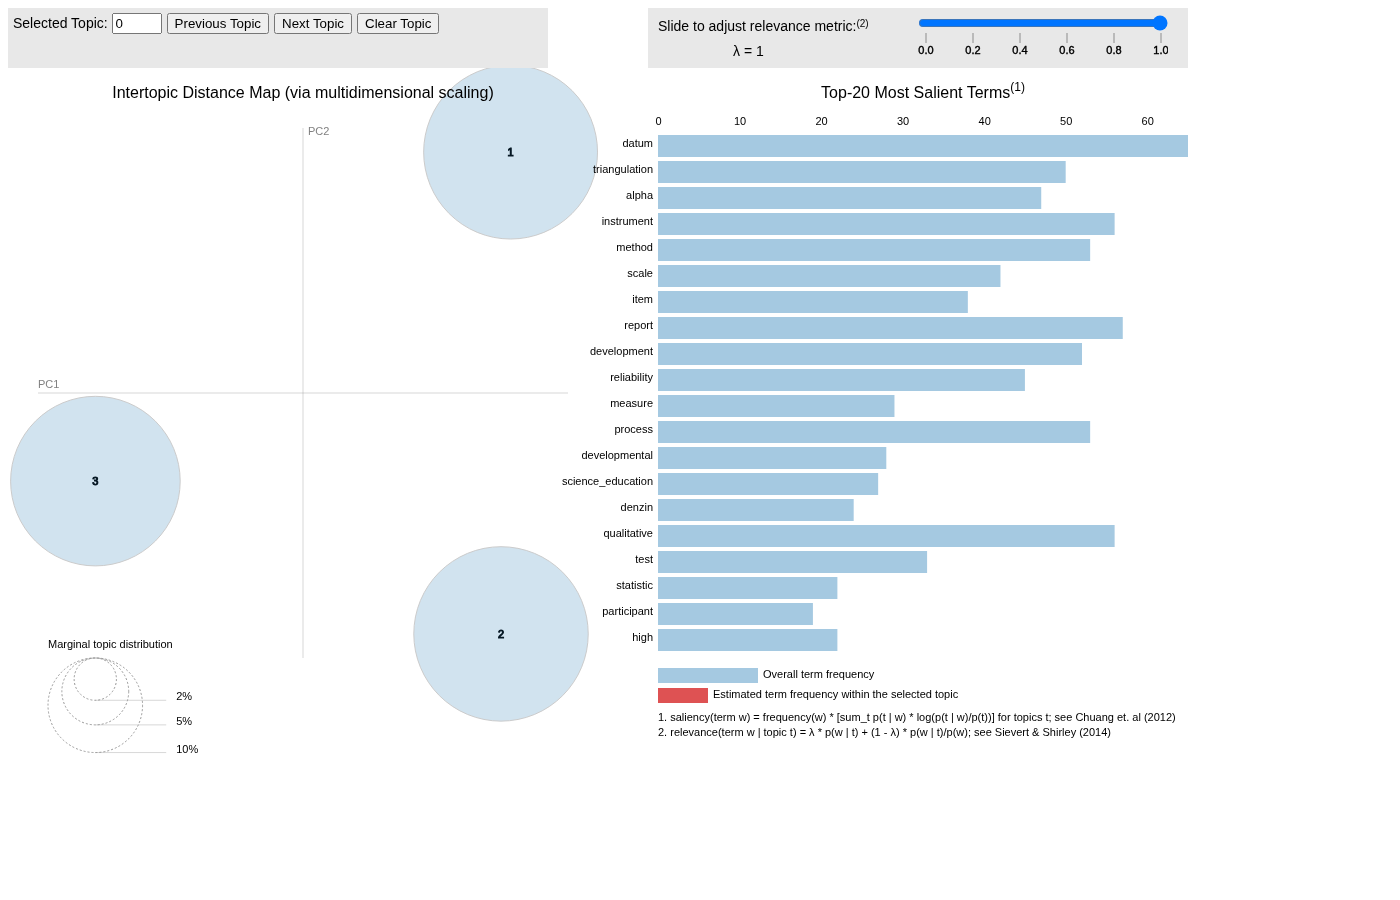

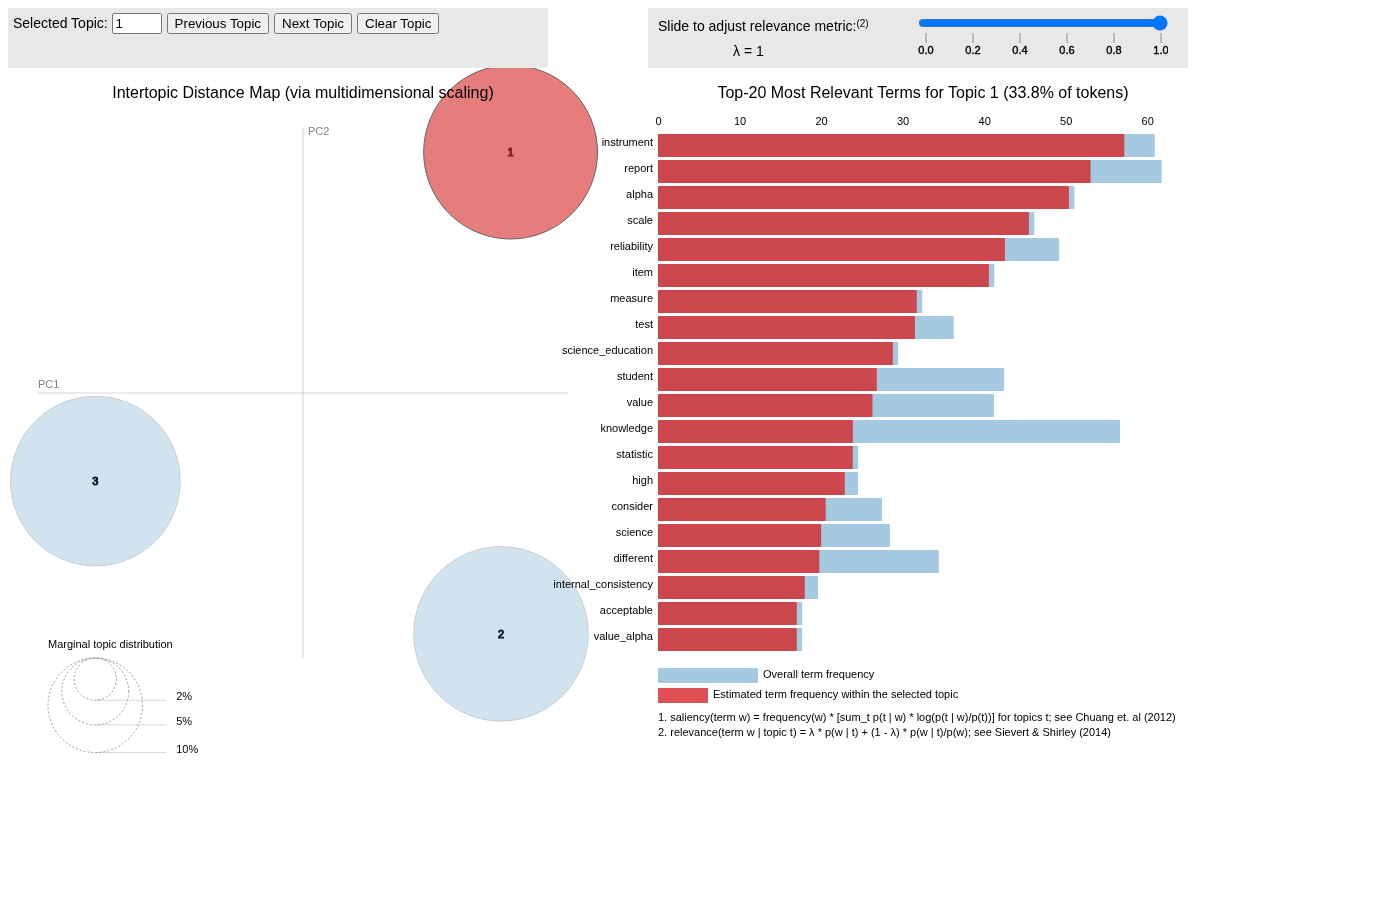

In [20]:
for f in ['q4_2_pyldavis_intertopic_map.png', 'q4_2_pyldavis_topic_selected.png']:
    if os.path.exists(f'{FIG}/{f}'): display(Image(f'{FIG}/{f}', width=900))

In [21]:
json.dump(results, open(f'{RES}/part_b_results.json', 'w'), indent=2, default=str); print('saved')

saved
